In [1]:
# =========================
# 🔷 WEEK 1: BREAKHIS (KAGGLEHUB + AUTO PATH DETECTION)
# =========================

# 🔹 1. Install
!pip install kagglehub --quiet

# 🔹 2. Imports
import os
import torch
import random
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
import kagglehub

# 🔹 3. Device Setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# 🔹 4. Seed
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed()

# 🔹 5. Download Dataset
path = kagglehub.dataset_download("ambarish/breakhis")
print("Downloaded to:", path)



Using device: cuda
GPU: Tesla T4


100%|██████████| 3.99G/3.99G [03:52<00:00, 18.4MB/s]

Extracting files...


Downloaded to: /root/.cache/kagglehub/datasets/ambarish/breakhis/versions/4


Using data directory: /root/.cache/kagglehub/datasets/ambarish/breakhis/versions/4/BreaKHis_v1/BreaKHis_v1/histology_slides/breast
Loaded 7909 images
Train size: 5536
Val size: 1186
Test size: 1187
Sample class distribution: Counter({0: 2000})


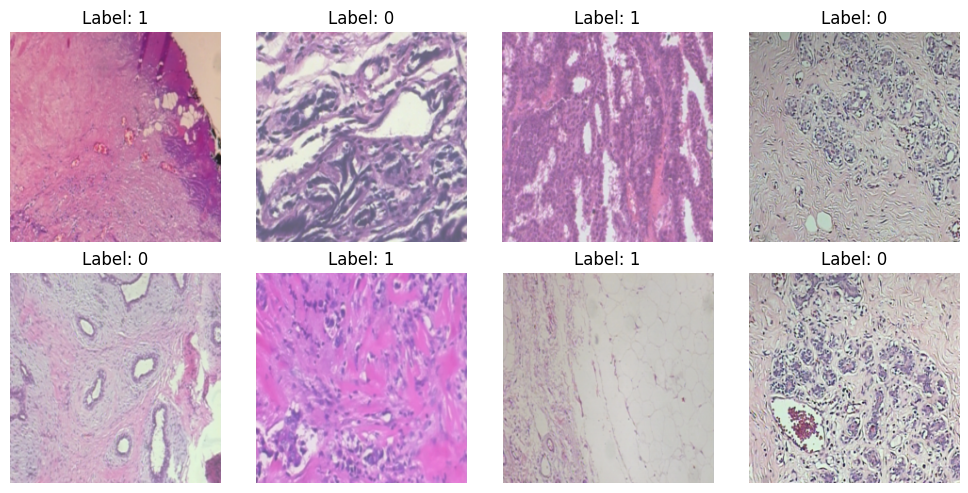

Batch shape: torch.Size([16, 3, 224, 224])
Labels shape: torch.Size([16])


In [2]:
# 🔹 6. 🔥 AUTO-DETECT DATA ROOT (IMPORTANT FIX)
def find_data_root(base_path):
    for root, dirs, files in os.walk(base_path):
        if "benign" in dirs and "malignant" in dirs:
            return root
    return None

data_dir = find_data_root(path)

if data_dir is None:
    raise ValueError("Could not find dataset root with 'benign' and 'malignant' folders")

print("Using data directory:", data_dir)

# 🔹 7. Transforms
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

# 🔹 8. Custom Dataset (handles nested folders)
class BreakHisDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.samples = []
        self.transform = transform

        for label, class_name in enumerate(["benign", "malignant"]):
            class_path = os.path.join(root_dir, class_name)

            for root, _, files in os.walk(class_path):
                for file in files:
                    if file.lower().endswith((".png", ".jpg", ".jpeg")):
                        self.samples.append((os.path.join(root, file), label))

        print(f"Loaded {len(self.samples)} images")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

# 🔹 9. Load Dataset
full_dataset = BreakHisDataset(data_dir, transform=train_transform)

# 🔹 10. Train / Val / Test Split
train_size = int(0.7 * len(full_dataset))
val_size   = int(0.15 * len(full_dataset))
test_size  = len(full_dataset) - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    full_dataset,
    [train_size, val_size, test_size]
)

# 🔥 Fix transforms for val/test
val_dataset.dataset.transform = val_test_transform
test_dataset.dataset.transform = val_test_transform

# 🔹 11. DataLoaders (stable config)
batch_size = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

# 🔹 12. Dataset Info
print("Train size:", len(train_dataset))
print("Val size:", len(val_dataset))
print("Test size:", len(test_dataset))

# 🔹 13. Class Distribution (sample)
from collections import Counter
labels = [full_dataset[i][1].item() for i in range(min(2000, len(full_dataset)))]
print("Sample class distribution:", Counter(labels))

# 🔹 14. Visualization

def denormalize(img):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    return img * std + mean

def show_batch(loader):
    images, labels = next(iter(loader))
    images = images.cpu()

    fig, axes = plt.subplots(2, 4, figsize=(10,5))
    axes = axes.flatten()

    for i in range(8):
        img = denormalize(images[i])
        img = img.permute(1,2,0).numpy()

        axes[i].imshow(img)
        axes[i].set_title(f"Label: {labels[i].item()}")
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()

show_batch(train_loader)

# 🔹 15. Sanity Check
images, labels = next(iter(train_loader))
print("Batch shape:", images.shape)
print("Labels shape:", labels.shape)


/tmp/ipykernel_1232/3653589321.py:82: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device.type == "cuda")


STAGE 1 : TRAIN CLASSIFIER


/tmp/ipykernel_1232/3653589321.py:122: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type == "cuda"):
/tmp/ipykernel_1232/3653589321.py:122: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type == "cuda"):


Epoch 01 | Train Loss 0.4850 | Train F1 0.8325 | Train AUC 0.8488
            Val Loss 0.3791 | Val F1 0.9127 | Val AUC 0.9314


/tmp/ipykernel_1232/3653589321.py:122: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type == "cuda"):
/tmp/ipykernel_1232/3653589321.py:122: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type == "cuda"):


...

Epoch 09 | Train Loss 0.0064 | Train F1 0.9989 | Train AUC 1.0000
            Val Loss 0.0608 | Val F1 0.9847 | Val AUC 0.9975


/tmp/ipykernel_1232/3653589321.py:122: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type == "cuda"):
/tmp/ipykernel_1232/3653589321.py:122: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type == "cuda"):


Epoch 10 | Train Loss 0.0079 | Train F1 0.9987 | Train AUC 0.9999
            Val Loss 0.0590 | Val F1 0.9878 | Val AUC 0.9976
FINAL TEST


/tmp/ipykernel_1232/3653589321.py:122: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type == "cuda"):


Loss      : 0.0759
Accuracy  : 0.9756
Precision : 0.9839
Recall    : 0.9802
F1        : 0.9820
ROC-AUC   : 0.9971


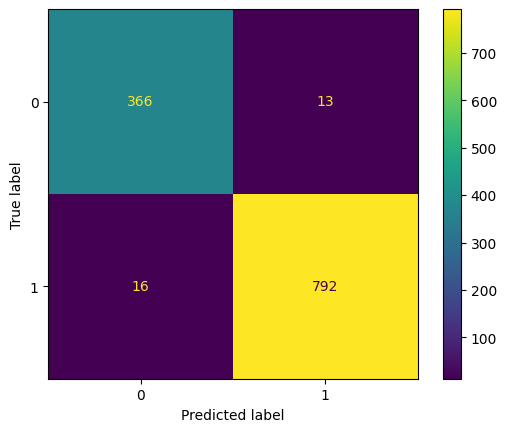

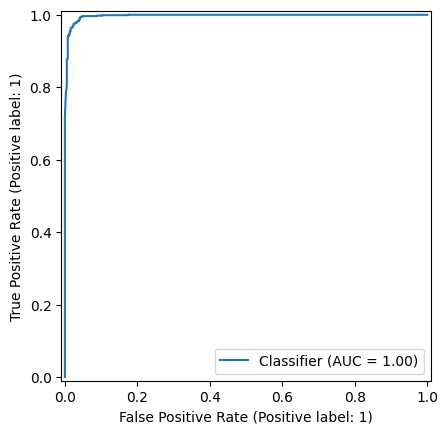

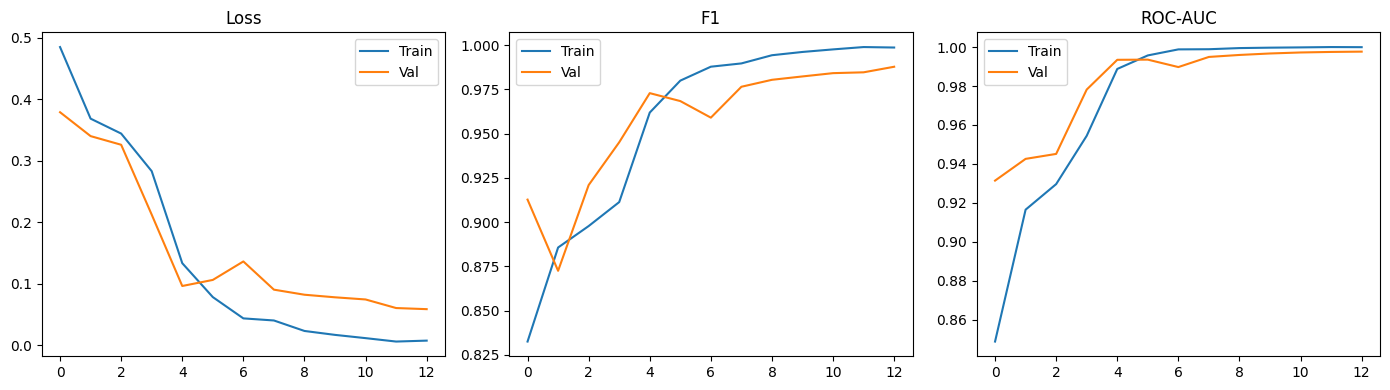

Best Validation ROC-AUC: 0.9976
Week 2 completed successfully.


In [24]:
"""
Week2_ResNet18_Corrected.py

Research-grade Week 2 pipeline for BreakHis.

Expected from Week 1:
    train_loader
    val_loader
    test_loader
    device

Features
--------
- ResNet18 pretrained
- Stage 1: Freeze backbone
- Stage 2: Fine tune entire network
- Weighted CrossEntropy
- AdamW
- CosineAnnealingLR
- AMP
- Accuracy / Precision / Recall / F1 / ROC-AUC
- Confusion Matrix
- ROC Curve
- Early stopping
- Best checkpoint
"""

import copy
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)

# ---------------------------------------------------
# Class weights
# ---------------------------------------------------
labels = []
for _, y in train_loader:
    labels.extend(y.cpu().numpy().tolist())

counts = np.bincount(labels)
weights = 1.0 / counts
weights = weights / weights.sum()

criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(weights, dtype=torch.float32).to(device)
)

# ---------------------------------------------------
# Model
# ---------------------------------------------------
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)
model.fc = nn.Linear(model.fc.in_features, 2)
model = model.to(device)

# Freeze backbone
for p in model.parameters():
    p.requires_grad = False

for p in model.fc.parameters():
    p.requires_grad = True

optimizer = optim.AdamW(model.fc.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=3)

scaler = torch.cuda.amp.GradScaler(enabled=device.type == "cuda")

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "train_f1": [],
    "val_f1": [],
    "train_auc": [],
    "val_auc": [],
}

best_auc = -1
best_model = None

# ---------------------------------------------------
# Epoch function
# ---------------------------------------------------
def run_epoch(loader, train=False):

    if train:
        model.train()
    else:
        model.eval()

    losses = []
    y_true = []
    y_pred = []
    y_score = []

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        if train:
            optimizer.zero_grad()

        with torch.set_grad_enabled(train):
            with torch.cuda.amp.autocast(enabled=device.type == "cuda"):
                outputs = model(images)
                loss = criterion(outputs, labels)

            if train:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        losses.append(loss.item())

        probs = torch.softmax(outputs, dim=1)[:, 1]

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(outputs.argmax(1).cpu().numpy())
        y_score.extend(probs.detach().cpu().numpy())

    metrics = {
        "loss": float(np.mean(losses)),
        "acc": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "auc": roc_auc_score(y_true, y_score),
        "cm": confusion_matrix(y_true, y_pred),
        "y_true": y_true,
        "y_score": y_score,
    }

    return metrics


# ---------------------------------------------------
# Stage function
# ---------------------------------------------------
def train_stage(num_epochs, stage_name, save_name, patience=5):

    global optimizer
    global scheduler
    global best_auc
    global best_model

    wait = 0

    print("=" * 70)
    print(stage_name)
    print("=" * 70)

    for epoch in range(num_epochs):

        train_metrics = run_epoch(train_loader, train=True)
        val_metrics = run_epoch(val_loader, train=False)

        scheduler.step()

        history["train_loss"].append(train_metrics["loss"])
        history["val_loss"].append(val_metrics["loss"])

        history["train_acc"].append(train_metrics["acc"])
        history["val_acc"].append(val_metrics["acc"])

        history["train_f1"].append(train_metrics["f1"])
        history["val_f1"].append(val_metrics["f1"])

        history["train_auc"].append(train_metrics["auc"])
        history["val_auc"].append(val_metrics["auc"])

        print(
            f"Epoch {epoch+1:02d} | "
            f"Train Loss {train_metrics['loss']:.4f} | "
            f"Train F1 {train_metrics['f1']:.4f} | "
            f"Train AUC {train_metrics['auc']:.4f}"
        )

        print(
            f"            "
            f"Val Loss {val_metrics['loss']:.4f} | "
            f"Val F1 {val_metrics['f1']:.4f} | "
            f"Val AUC {val_metrics['auc']:.4f}"
        )

        if val_metrics["auc"] > best_auc:
            best_auc = val_metrics["auc"]
            best_model = copy.deepcopy(model.state_dict())
            torch.save(best_model, save_name)
            wait = 0
        else:
            wait += 1

        if wait >= patience:
            print("Early stopping.")
            break


# ---------------------------------------------------
# Stage 1
# ---------------------------------------------------
train_stage(
    num_epochs=3,
    stage_name="STAGE 1 : TRAIN CLASSIFIER",
    save_name="best_resnet18_stage1.pth",
)

# ---------------------------------------------------
# Stage 2
# ---------------------------------------------------
for p in model.parameters():
    p.requires_grad = True

optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)

train_stage(
    num_epochs=10,
    stage_name="STAGE 2 : FINE TUNING",
    save_name="best_resnet18.pth",
)

# ---------------------------------------------------
# Testing
# ---------------------------------------------------
model.load_state_dict(best_model)

print("=" * 70)
print("FINAL TEST")
print("=" * 70)

test_metrics = run_epoch(test_loader, train=False)

print(f"Loss      : {test_metrics['loss']:.4f}")
print(f"Accuracy  : {test_metrics['acc']:.4f}")
print(f"Precision : {test_metrics['precision']:.4f}")
print(f"Recall    : {test_metrics['recall']:.4f}")
print(f"F1        : {test_metrics['f1']:.4f}")
print(f"ROC-AUC   : {test_metrics['auc']:.4f}")

ConfusionMatrixDisplay(test_metrics["cm"]).plot()
plt.show()

RocCurveDisplay.from_predictions(
    test_metrics["y_true"],
    test_metrics["y_score"],
)
plt.show()

plt.figure(figsize=(14,4))

plt.subplot(1,3,1)
plt.plot(history["train_loss"], label="Train")
plt.plot(history["val_loss"], label="Val")
plt.title("Loss")
plt.legend()

plt.subplot(1,3,2)
plt.plot(history["train_f1"], label="Train")
plt.plot(history["val_f1"], label="Val")
plt.title("F1")
plt.legend()

plt.subplot(1,3,3)
plt.plot(history["train_auc"], label="Train")
plt.plot(history["val_auc"], label="Val")
plt.title("ROC-AUC")
plt.legend()

plt.tight_layout()
plt.show()

print(f"Best Validation ROC-AUC: {best_auc:.4f}")
print("Week 2 completed successfully.")


In [26]:
from google.colab import drive
drive.mount('/content/drive')
import torch

# Define a path inside your Google Drive
MODEL_PATH = '/content/drive/MyDrive/model_cnn.pt'

# Save the weights
torch.save(model.state_dict(), MODEL_PATH)
print("Model successfully saved to Google Drive!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model successfully saved to Google Drive!


In [31]:
import torch
from torchvision import models
import torch.nn as nn

# Assuming 'device' is already defined from Week 1 setup (e.g., 'cuda' or 'cpu')
# If not, you might need to run the Week 1 cell that defines 'device'
# For demonstration, we'll assume it's available or define it here if needed:
if 'device' not in locals():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Device not found, defaulting to: {device}")

# 1. Initialize the model architecture (ResNet18 with 2 output classes)
weights = models.ResNet18_Weights.DEFAULT
model_cnn = models.resnet18(weights=weights)
model_cnn.fc = nn.Linear(model_cnn.fc.in_features, 2)
model_cnn = model_cnn.to(device)

# 2. Load the state_dict into the initialized model
state_dict = torch.load('/content/drive/MyDrive/model_cnn.pt', weights_only=False)
model_cnn.load_state_dict(state_dict)

# 3. Set the model to evaluation mode
model_cnn.eval()
#print("CNN model loaded successfully and set to evaluation mode.")

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:124: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/22.9M [00:00<?, ?B/s]

/tmp/ipykernel_1232/1324425229.py:85: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler=torch.cuda.amp.GradScaler(enabled=device.type=="cuda")


Stage 1 : Train Classification Head


/tmp/ipykernel_1232/1324425229.py:121: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type=="cuda"):
/tmp/ipykernel_1232/1324425229.py:121: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type=="cuda"):


...


Epoch 9
Train: {'loss': np.float64(0.00010965904262270296), 'acc': 1.0, 'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'auc': np.float64(1.0)}
Val  : {'loss': np.float64(0.08585280024075473), 'acc': 0.9839797639123102, 'precision': 0.9902200488997555, 'recall': 0.9866017052375152, 'f1': 0.9884075655887736, 'auc': np.float64(0.9965544858425242)}


/tmp/ipykernel_1232/1324425229.py:121: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type=="cuda"):
/tmp/ipykernel_1232/1324425229.py:121: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type=="cuda"):



Epoch 10
Train: {'loss': np.float64(9.375685500051426e-05), 'acc': 1.0, 'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'auc': np.float64(1.0)}
Val  : {'loss': np.float64(0.08598840445239452), 'acc': 0.9839797639123102, 'precision': 0.9902200488997555, 'recall': 0.9866017052375152, 'f1': 0.9884075655887736, 'auc': np.float64(0.9965644970216742)}
Early stopping.
Testing


/tmp/ipykernel_1232/1324425229.py:121: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type=="cuda"):


loss: 0.08410668858196005
acc: 0.974726200505476
precision: 0.979064039408867
recall: 0.9839108910891089
f1: 0.9814814814814815
auc: 0.9965369393139841


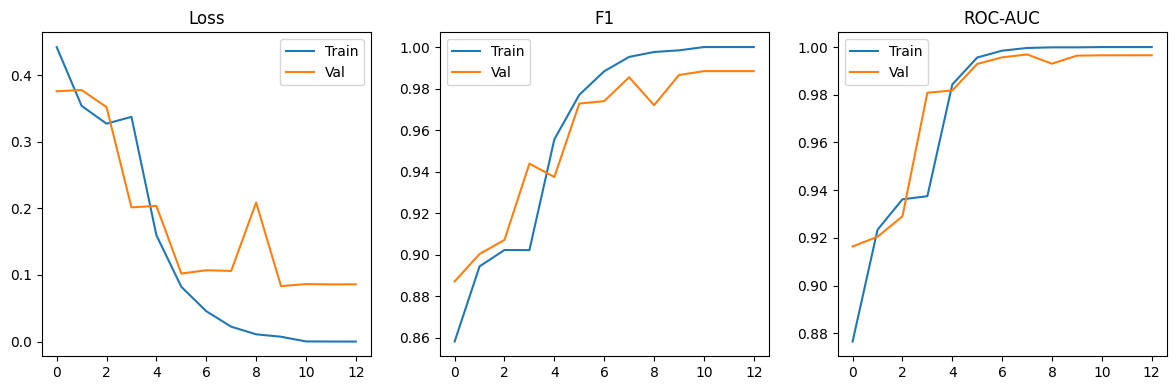

\nBest Validation AUC: 0.9969048771127759
Week 3 complete.


In [11]:
"""
Week3_ViTTiny.py

Week 3: Vision Transformer Tiny baseline for BreakHis.
Expected from Week 1:
    train_loader, val_loader, test_loader, device

Features:
- timm ViT Tiny pretrained
- Freeze -> Fine-tune
- AdamW
- CosineAnnealingLR
- AMP
- Accuracy / Precision / Recall / F1 / ROC-AUC
- Best checkpoint
"""

import copy
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from torchvision.transforms import Resize
import timm

try:
    import matplotlib.pyplot as plt
except:
    plt = None

# ----------------------------
# Install timm if missing
# ----------------------------
try:
    timm.list_models()
except Exception:
    import subprocess, sys
    subprocess.check_call([sys.executable,"-m","pip","install","timm"])

# ----------------------------
# Compute class weights
# ----------------------------
labels=[]
for _,y in train_loader:
    labels.extend(y.tolist())

counts=np.bincount(labels)
weights=1/counts
weights=weights/weights.sum()

criterion=nn.CrossEntropyLoss(
    weight=torch.tensor(weights,dtype=torch.float32).to(device)
)

# ----------------------------
# Build ViT Tiny
# ----------------------------
model=timm.create_model(
    "vit_tiny_patch16_224",
    pretrained=True,
    num_classes=2
).to(device)

# ----------------------------
# Freeze backbone
# ----------------------------
for p in model.parameters():
    p.requires_grad=False

for p in model.head.parameters():
    p.requires_grad=True

optimizer=optim.AdamW(
    model.head.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

scheduler=optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=3
)

scaler=torch.cuda.amp.GradScaler(enabled=device.type=="cuda")

history={
    "train_loss":[],
    "val_loss":[],
    "train_f1":[],
    "val_f1":[],
    "train_auc":[],
    "val_auc":[]
}

best_auc=-1
best_model=None

def run_epoch(loader,train=True):

    if train:
        model.train()
    else:
        model.eval()

    losses=[]

    y_true=[]
    y_pred=[]
    y_score=[]

    for x,y in loader:

        x=x.to(device)
        y=y.to(device)

        if train:
            optimizer.zero_grad()

        with torch.set_grad_enabled(train):
            with torch.cuda.amp.autocast(enabled=device.type=="cuda"):

                out=model(x)
                loss=criterion(out,y)

            if train:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        losses.append(loss.item())

        prob=torch.softmax(out,1)[:,1]

        y_true.extend(y.cpu().numpy())
        y_pred.extend(out.argmax(1).cpu().numpy())
        y_score.extend(prob.detach().cpu().numpy())

    metrics={
        "loss":np.mean(losses),
        "acc":accuracy_score(y_true,y_pred),
        "precision":precision_score(y_true,y_pred,zero_division=0),
        "recall":recall_score(y_true,y_pred,zero_division=0),
        "f1":f1_score(y_true,y_pred,zero_division=0),
        "auc":roc_auc_score(y_true,y_score)
    }

    return metrics

print("="*60)
print("Stage 1 : Train Classification Head")
print("="*60)

for epoch in range(3):

    tr=run_epoch(train_loader,True)
    vl=run_epoch(val_loader,False)

    scheduler.step()

    history["train_loss"].append(tr["loss"])
    history["val_loss"].append(vl["loss"])
    history["train_f1"].append(tr["f1"])
    history["val_f1"].append(vl["f1"])
    history["train_auc"].append(tr["auc"])
    history["val_auc"].append(vl["auc"])

    print(f"\nEpoch {epoch+1}")
    print("Train:",tr)
    print("Val  :",vl)

    if vl["auc"]>best_auc:
        best_auc=vl["auc"]
        best_model=copy.deepcopy(model.state_dict())
        torch.save(best_model,"best_vit_tiny_stage1.pth")

print("="*60)
print("Stage 2 : Fine Tuning")
print("="*60)

for p in model.parameters():
    p.requires_grad=True

optimizer=optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler=optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=10
)

patience=5
counter=0

for epoch in range(10):

    tr=run_epoch(train_loader,True)
    vl=run_epoch(val_loader,False)

    scheduler.step()

    history["train_loss"].append(tr["loss"])
    history["val_loss"].append(vl["loss"])
    history["train_f1"].append(tr["f1"])
    history["val_f1"].append(vl["f1"])
    history["train_auc"].append(tr["auc"])
    history["val_auc"].append(vl["auc"])

    print(f"\nEpoch {epoch+1}")
    print("Train:",tr)
    print("Val  :",vl)

    if vl["auc"]>best_auc:
        best_auc=vl["auc"]
        best_model=copy.deepcopy(model.state_dict())
        torch.save(best_model,"best_vit_tiny.pth")
        counter=0
    else:
        counter+=1

    if counter>=patience:
        print("Early stopping.")
        break

model.load_state_dict(best_model)

print("="*60)
print("Testing")
print("="*60)

test=run_epoch(test_loader,False)

for k,v in test.items():
    print(f"{k}: {v}")

if plt is not None:
    plt.figure(figsize=(12,4))

    plt.subplot(131)
    plt.plot(history["train_loss"],label="Train")
    plt.plot(history["val_loss"],label="Val")
    plt.title("Loss")
    plt.legend()

    plt.subplot(132)
    plt.plot(history["train_f1"],label="Train")
    plt.plot(history["val_f1"],label="Val")
    plt.title("F1")
    plt.legend()

    plt.subplot(133)
    plt.plot(history["train_auc"],label="Train")
    plt.plot(history["val_auc"],label="Val")
    plt.title("ROC-AUC")
    plt.legend()

    plt.tight_layout()
    plt.show()

print("\\nBest Validation AUC:",best_auc)
print("Week 3 complete.")


In [41]:
from google.colab import drive
drive.mount('/content/drive')
import torch

# Define a path inside your Google Drive
MODEL_PATH = '/content/drive/MyDrive/model_vit.pt'

# Save the weights (best_model is confirmed to be a state_dict from training cell EXYeQlfwgyU_)
torch.save(best_model, MODEL_PATH)
print("Model successfully saved to Google Drive!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model successfully saved to Google Drive!


In [44]:
import torch
import timm # Ensure timm is imported

# Assuming 'device' is already defined (e.g., from Week 1 setup)
if 'device' not in locals():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Device not found, defaulting to: {device}")

# Instantiate the ViT-Tiny model architecture.
# The weights will be loaded by the comparison script from the .pt file.
model_vit = timm.create_model(
    "vit_tiny_patch16_224",
    pretrained=False, # We are not using pre-trained weights here, but loading our own
    num_classes=2
).to(device)
model_vit.eval()
# No state_dict loading or .eval() here, as compare_models.py will handle that.
#print("ViT-Tiny model architecture instantiated for comparison.")

VisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 192, kernel_size=(16, 16), stride=(16, 16))
    (norm): Identity()
  )
  (pos_drop): Dropout(p=0.0, inplace=False)
  (patch_drop): Identity()
  (norm_pre): Identity()
  (blocks): Sequential(
    (0): Block(
      (norm1): LayerNorm((192,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=192, out_features=576, bias=True)
        (q_norm): Identity()
        (k_norm): Identity()
        (attn_drop): Dropout(p=0.0, inplace=False)
        (norm): Identity()
        (proj): Linear(in_features=192, out_features=192, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): Identity()
      (drop_path1): Identity()
      (norm2): LayerNorm((192,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=192, out_features=768, bias=True)
        (act): GELU(approximate='none')
        (drop1): Dropout(p=0.0, inplace=False)


/tmp/ipykernel_1232/1017855771.py:163: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  self.transformer=nn.TransformerEncoder(
/tmp/ipykernel_1232/1017855771.py:221: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler=torch.cuda.amp.GradScaler(enabled=device.type=="cuda")
/tmp/ipykernel_1232/1017855771.py:252: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type=="cuda"):
/tmp/ipykernel_1232/1017855771.py:252: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type=="cuda"):



Epoch 1
{'loss': np.float64(0.30518766339717573), 'acc': 0.8710260115606936, 'precision': 0.9393507972665148, 'recall': 0.8681578947368421, 'f1': 0.9023522975929978, 'auc': np.float64(0.9432427085859811)}
{'loss': np.float64(0.14342555458347003), 'acc': 0.9586846543001686, 'precision': 0.9650602409638555, 'recall': 0.9756394640682094, 'f1': 0.970321017565112, 'auc': np.float64(0.9890277476515441)}


/tmp/ipykernel_1232/1017855771.py:252: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type=="cuda"):
/tmp/ipykernel_1232/1017855771.py:252: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type=="cuda"):



Epoch 2
{'loss': np.float64(0.1608281089746625), 'acc': 0.9398482658959537, 'precision': 0.9704206241519674, 'recall': 0.9410526315789474, 'f1': 0.9555110220440882, 'auc': np.float64(0.9836118269463981)}
{'loss': np.float64(0.1452310398221016), 'acc': 0.948566610455312, 'precision': 0.9714640198511166, 'recall': 0.953714981729598, 'f1': 0.9625076828518746, 'auc': np.float64(0.9867001484991574)}


/tmp/ipykernel_1232/1017855771.py:252: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type=="cuda"):
/tmp/ipykernel_1232/1017855771.py:252: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type=="cuda"):


...


Epoch 14
{'loss': np.float64(0.002989519404769253), 'acc': 0.9987355491329479, 'precision': 0.9997364953886693, 'recall': 0.998421052631579, 'f1': 0.9990783410138249, 'auc': np.float64(0.999996513461072)}
{'loss': np.float64(0.06954371793797084), 'acc': 0.9814502529510961, 'precision': 0.991389913899139, 'recall': 0.9817295980511571, 'f1': 0.9865361077111383, 'auc': np.float64(0.9980261291775817)}


/tmp/ipykernel_1232/1017855771.py:252: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type=="cuda"):
/tmp/ipykernel_1232/1017855771.py:252: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type=="cuda"):



Epoch 15
{'loss': np.float64(0.0032063480061169367), 'acc': 0.9992774566473989, 'precision': 0.9994736842105263, 'recall': 0.9994736842105263, 'f1': 0.9994736842105263, 'auc': np.float64(0.999996513461072)}
{'loss': np.float64(0.07807582594813235), 'acc': 0.9806070826306914, 'precision': 0.9877750611246944, 'recall': 0.9841656516443362, 'f1': 0.9859670530811471, 'auc': np.float64(0.9964593796405986)}


/tmp/ipykernel_1232/1017855771.py:252: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type=="cuda"):



Final Test Metrics
loss: 0.07139438438772534
acc: 0.9848357203032856
precision: 0.9900744416873449
recall: 0.9876237623762376
f1: 0.9888475836431226
auc: 0.9978480367825701


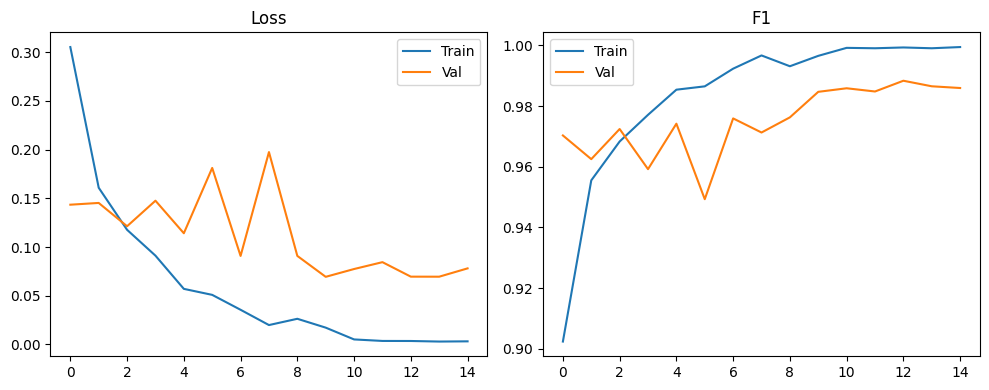


Week 4 completed successfully.


In [33]:
"""
Week4_HybridCNN_ViT.py

Week 4: Lightweight Hybrid CNN-ViT Architecture
------------------------------------------------

Expected from Week 1:
    train_loader
    val_loader
    test_loader
    device

This file focuses on BUILDING and TRAINING the proposed hybrid model.

Architecture
------------
Input
  ↓
ResNet18 Backbone (without classifier)
  ↓
1x1 Projection
  ↓
Depthwise Feature Fusion
  ↓
Conv Tokenizer
  ↓
Learnable Position Embedding
  ↓
Transformer Encoder x2
  ↓
ECA Attention
  ↓
Global Average Pool
  ↓
MLP Classifier
"""

import copy
import math
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

from sklearn.metrics import accuracy_score,f1_score,precision_score,recall_score,roc_auc_score

# -----------------------------
# Class weights
# -----------------------------
labels=[]
for _,y in train_loader:
    labels.extend(y.tolist())

counts=np.bincount(labels)
weights=1/counts
weights=weights/weights.sum()

criterion=nn.CrossEntropyLoss(
    weight=torch.tensor(weights,dtype=torch.float32).to(device)
)

# -----------------------------
# ECA Block
# -----------------------------
class ECABlock(nn.Module):
    def __init__(self,channels,k_size=3):
        super().__init__()
        self.pool=nn.AdaptiveAvgPool1d(1)
        self.conv=nn.Conv1d(1,1,kernel_size=k_size,padding=(k_size-1)//2,bias=False)
        self.sigmoid=nn.Sigmoid()

    def forward(self,x):
        # x : B N C
        y=x.transpose(1,2)
        y=self.pool(y)
        y=y.transpose(1,2)
        y=self.conv(y)
        y=self.sigmoid(y)
        return x*y

# -----------------------------
# Lightweight Feature Fusion
# -----------------------------
class FeatureFusion(nn.Module):

    def __init__(self,channels):
        super().__init__()

        self.dw=nn.Conv2d(
            channels,
            channels,
            3,
            padding=1,
            groups=channels
        )

        self.pw=nn.Conv2d(
            channels,
            channels,
            1
        )

        self.bn=nn.BatchNorm2d(channels)
        self.act=nn.GELU()

    def forward(self,x):
        identity=x
        x=self.dw(x)
        x=self.pw(x)
        x=self.bn(x)
        x=self.act(x)
        return x+identity

# -----------------------------
# Hybrid Model
# -----------------------------
class HybridCNNViT(nn.Module):

    def __init__(
        self,
        embed_dim=192,
        depth=2,
        heads=3,
        dropout=0.1
    ):
        super().__init__()

        backbone=models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

        self.backbone=nn.Sequential(*list(backbone.children())[:-2])

        self.project=nn.Conv2d(
            512,
            embed_dim,
            kernel_size=1
        )

        self.fusion=FeatureFusion(embed_dim)

        self.tokenizer=nn.Conv2d(
            embed_dim,
            embed_dim,
            kernel_size=3,
            padding=1
        )

        self.pos_embed=nn.Parameter(
            torch.randn(1,49,embed_dim)
        )

        encoder=nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=heads,
            dim_feedforward=embed_dim*4,
            dropout=dropout,
            activation="gelu",
            batch_first=True
        )

        self.transformer=nn.TransformerEncoder(
            encoder,
            num_layers=depth
        )

        self.eca=ECABlock(embed_dim)

        self.norm=nn.LayerNorm(embed_dim)

        self.head=nn.Sequential(
            nn.Linear(embed_dim,128),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(128,2)
        )

    def forward(self,x):

        x=self.backbone(x)

        x=self.project(x)

        x=self.fusion(x)

        x=self.tokenizer(x)

        B,C,H,W=x.shape

        x=x.flatten(2).transpose(1,2)

        x=x+self.pos_embed[:,:x.size(1)]

        x=self.transformer(x)

        x=self.eca(x)

        x=self.norm(x)

        x=x.mean(dim=1)

        return self.head(x)

# -----------------------------
# Model
# -----------------------------
model=HybridCNNViT().to(device)

optimizer=optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler=optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=15
)

scaler=torch.cuda.amp.GradScaler(enabled=device.type=="cuda")

history={"train_loss":[],"val_loss":[],"train_f1":[],"val_f1":[]}

best_f1=0
best_state=None

# -----------------------------
# Epoch
# -----------------------------
def epoch(loader,train):

    if train:
        model.train()
    else:
        model.eval()

    losses=[]
    yt=[]
    yp=[]
    ys=[]

    for x,y in loader:

        x=x.to(device)
        y=y.to(device)

        if train:
            optimizer.zero_grad()

        with torch.set_grad_enabled(train):
            with torch.cuda.amp.autocast(enabled=device.type=="cuda"):
                out=model(x)
                loss=criterion(out,y)

            if train:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        losses.append(loss.item())

        prob=torch.softmax(out,1)[:,1]

        yt.extend(y.cpu().numpy())
        yp.extend(out.argmax(1).cpu().numpy())
        ys.extend(prob.detach().cpu().numpy())

    return {
        "loss":np.mean(losses),
        "acc":accuracy_score(yt,yp),
        "precision":precision_score(yt,yp,zero_division=0),
        "recall":recall_score(yt,yp,zero_division=0),
        "f1":f1_score(yt,yp,zero_division=0),
        "auc":roc_auc_score(yt,ys)
    }

# -----------------------------
# Training
# -----------------------------
patience=5
wait=0

for e in range(15):

    tr=epoch(train_loader,True)
    vl=epoch(val_loader,False)

    scheduler.step()

    history["train_loss"].append(tr["loss"])
    history["val_loss"].append(vl["loss"])
    history["train_f1"].append(tr["f1"])
    history["val_f1"].append(vl["f1"])

    print(f"\nEpoch {e+1}")
    print(tr)
    print(vl)

    if vl["f1"]>best_f1:
        best_f1=vl["f1"]
        best_state=copy.deepcopy(model.state_dict())
        torch.save(best_state,"best_hybrid.pth")
        wait=0
    else:
        wait+=1

    if wait>=patience:
        print("Early stopping.")
        break

# -----------------------------
# Test
# -----------------------------
model.load_state_dict(best_state)

test=epoch(test_loader,False)

print("\nFinal Test Metrics")
for k,v in test.items():
    print(f"{k}: {v}")

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(history["train_loss"],label="Train")
plt.plot(history["val_loss"],label="Val")
plt.legend()
plt.title("Loss")

plt.subplot(1,2,2)
plt.plot(history["train_f1"],label="Train")
plt.plot(history["val_f1"],label="Val")
plt.legend()
plt.title("F1")

plt.tight_layout()
plt.show()

print("\nWeek 4 completed successfully.")


In [34]:
from google.colab import drive
drive.mount('/content/drive')
import torch

# Define a path inside your Google Drive
MODEL_PATH = '/content/drive/MyDrive/model_hybrid.pt'

# Save the weights
torch.save(model.state_dict(), MODEL_PATH)
print("Model successfully saved to Google Drive!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model successfully saved to Google Drive!


In [37]:
import torch
import torch.nn as nn
from torchvision import models

# Assuming 'device' is already defined (e.g., from Week 1 setup)
if 'device' not in locals():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Device not found, defaulting to: {device}")

# Re-define the ECABlock class if it's not globally available in the notebook
# This is crucial if this cell is run independently and ECABlock isn't defined above it
class ECABlock(nn.Module):
    def __init__(self,channels,k_size=3):
        super().__init__()
        self.pool=nn.AdaptiveAvgPool1d(1)
        self.conv=nn.Conv1d(1,1,kernel_size=k_size,padding=(k_size-1)//2,bias=False)
        self.sigmoid=nn.Sigmoid()

    def forward(self,x):
        # x : B N C
        y=x.transpose(1,2)
        y=self.pool(y)
        y=y.transpose(1,2)
        y=self.conv(y)
        y=self.sigmoid(y)
        return x*y

# Re-define the FeatureFusion class if it's not globally available in the notebook
class FeatureFusion(nn.Module):

    def __init__(self,channels):
        super().__init__()

        self.dw=nn.Conv2d(
            channels,
            channels,
            3,
            padding=1,
            groups=channels
        )

        self.pw=nn.Conv2d(
            channels,
            channels,
            1
        )

        self.bn=nn.BatchNorm2d(channels)
        self.act=nn.GELU()

    def forward(self,x):
        identity=x
        x=self.dw(x)
        x=self.pw(x)
        x=self.bn(x)
        x=self.act(x)
        return x+identity

# Re-define the HybridCNNViT class
class HybridCNNViT(nn.Module):

    def __init__(
        self,
        embed_dim=192,
        depth=2,
        heads=3,
        dropout=0.1
    ):
        super().__init__()

        backbone=models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

        self.backbone=nn.Sequential(*list(backbone.children())[:-2])

        self.project=nn.Conv2d(
            512,
            embed_dim,
            kernel_size=1
        )

        self.fusion=FeatureFusion(embed_dim)

        self.tokenizer=nn.Conv2d(
            embed_dim,
            embed_dim,
            kernel_size=3,
            padding=1
        )

        self.pos_embed=nn.Parameter(
            torch.randn(1,49,embed_dim)
        )

        encoder=nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=heads,
            dim_feedforward=embed_dim*4,
            dropout=dropout,
            activation="gelu",
            batch_first=True
        )

        self.transformer=nn.TransformerEncoder(
            encoder,
            num_layers=depth
        )

        self.eca=ECABlock(embed_dim)

        self.norm=nn.LayerNorm(embed_dim)

        self.head=nn.Sequential(
            nn.Linear(embed_dim,128),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(128,2)
        )

    def forward(self,x):

        x=self.backbone(x)

        x=self.project(x)

        x=self.fusion(x)

        x=self.tokenizer(x)

        B,C,H,W=x.shape

        x=x.flatten(2).transpose(1,2)

        x=x+self.pos_embed[:,:x.size(1)]

        x=self.transformer(x)

        x=self.eca(x)

        x=self.norm(x)

        x=x.mean(dim=1)

        return self.head(x)

# 1. Instantiate the HybridCNNViT model
model_hybrid = HybridCNNViT().to(device)

# 2. Load the state_dict into the initialized model
state_dict_hybrid = torch.load('/content/drive/MyDrive/model_hybrid.pt', weights_only=False)
model_hybrid.load_state_dict(state_dict_hybrid)

# 3. Set the model to evaluation mode
model_hybrid.eval()
#print("Hybrid model loaded successfully and set to evaluation mode.")

/tmp/ipykernel_1232/934011224.py:103: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  self.transformer=nn.TransformerEncoder(


HybridCNNViT(
  (backbone): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats

In [47]:
# =========================
# 🔷 WEEK 5: MODEL COMPARISON
# =========================

import numpy as np
import torch
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 🔹 1. Shared eval function
def evaluate(model, loader):
    model.eval()
    yt, yp, ys = [], [], []

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            prob = torch.softmax(out, 1)[:, 1]
            yt.extend(y.cpu().numpy())
            yp.extend(out.argmax(1).cpu().numpy())
            ys.extend(prob.cpu().numpy())

    return {
        "acc":       accuracy_score(yt, yp),
        "precision": precision_score(yt, yp, zero_division=0),
        "recall":    recall_score(yt, yp, zero_division=0),
        "f1":        f1_score(yt, yp, zero_division=0),
        "auc":       roc_auc_score(yt, ys),
        "y_true":    yt,
        "y_score":   ys,
    }

# 🔹 2. Run evaluation on all three models
print("Evaluating models on test set...")

results_cnn    = evaluate(model_cnn, test_loader)
results_vit    = evaluate(model_vit, test_loader)
results_hybrid = evaluate(model_hybrid, test_loader)

# 🔹 3. Print comparison table
metrics = ["acc", "precision", "recall", "f1", "auc"]

print(f"\n{'Metric':<12} {'ResNet18':>10} {'ViT-Tiny':>10} {'Hybrid':>10}")
print("-" * 44)
for m in metrics:
    print(f"{m:<12} {results_cnn[m]:>10.4f} {results_vit[m]:>10.4f} {results_hybrid[m]:>10.4f}")

Evaluating models on test set...

Metric         ResNet18   ViT-Tiny     Hybrid
--------------------------------------------
acc              0.9756     0.3791     0.9848
precision        0.9839     0.8901     0.9901
recall           0.9802     0.1002     0.9876
f1               0.9820     0.1802     0.9888
auc              0.9971     0.7312     0.9979


In [48]:
# =========================
# 🔷 WEEK 5: ABLATION STUDY
# =========================

import copy
import torch
import torch.nn as nn
import numpy as np
from sklearn.metrics import f1_score, roc_auc_score, accuracy_score

# 🔹 Ablation: remove components one at a time from HybridCNNViT

# --- Variant A: No ECA (replace with identity) ---
class HybridNoECA(HybridCNNViT):
    def forward(self, x):
        x = self.backbone(x)
        x = self.project(x)
        x = self.fusion(x)
        x = self.tokenizer(x)
        B, C, H, W = x.shape
        x = x.flatten(2).transpose(1, 2)
        x = x + self.pos_embed[:, :x.size(1)]
        x = self.transformer(x)
        # ECA skipped
        x = self.norm(x)
        x = x.mean(dim=1)
        return self.head(x)

# --- Variant B: No Fusion (replace with identity) ---
class HybridNoFusion(HybridCNNViT):
    def forward(self, x):
        x = self.backbone(x)
        x = self.project(x)
        # Fusion skipped
        x = self.tokenizer(x)
        B, C, H, W = x.shape
        x = x.flatten(2).transpose(1, 2)
        x = x + self.pos_embed[:, :x.size(1)]
        x = self.transformer(x)
        x = self.eca(x)
        x = self.norm(x)
        x = x.mean(dim=1)
        return self.head(x)

# --- Variant C: No Transformer (pool directly after fusion) ---
class HybridNoTransformer(nn.Module):
    def __init__(self, embed_dim=192, dropout=0.1):
        super().__init__()
        backbone = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        self.backbone = nn.Sequential(*list(backbone.children())[:-2])
        self.project  = nn.Conv2d(512, embed_dim, 1)
        self.fusion   = FeatureFusion(embed_dim)
        self.pool     = nn.AdaptiveAvgPool2d(1)
        self.head     = nn.Sequential(
            nn.Linear(embed_dim, 128),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        x = self.backbone(x)
        x = self.project(x)
        x = self.fusion(x)
        x = self.pool(x).flatten(1)
        return self.head(x)

# 🔹 Load weights into ablation variants (from best hybrid checkpoint)
def load_ablation(cls, path='/content/drive/MyDrive/model_hybrid.pt'):
    m = cls().to(device)
    state = torch.load(path, weights_only=False)
    m.load_state_dict(state, strict=False)   # strict=False ignores missing keys
    m.eval()
    return m

model_no_eca        = load_ablation(HybridNoECA)
model_no_fusion     = load_ablation(HybridNoFusion)
model_no_transformer= HybridNoTransformer().to(device)   # random init — fair ablation
model_no_transformer.eval()

# 🔹 Evaluate all ablation variants
ablation_models = {
    "Full Hybrid":      model_hybrid,
    "No ECA":           model_no_eca,
    "No Fusion":        model_no_fusion,
    "No Transformer":   model_no_transformer,
}

ablation_results = {}
for name, m in ablation_models.items():
    ablation_results[name] = evaluate(m, test_loader)

# 🔹 Print ablation table
print(f"\n{'Variant':<20} {'Acc':>8} {'F1':>8} {'AUC':>8}")
print("-" * 46)
for name, res in ablation_results.items():
    print(f"{name:<20} {res['acc']:>8.4f} {res['f1']:>8.4f} {res['auc']:>8.4f}")

/tmp/ipykernel_1232/934011224.py:103: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  self.transformer=nn.TransformerEncoder(



Variant                   Acc       F1      AUC
----------------------------------------------
Full Hybrid            0.9848   0.9888   0.9979
No ECA                 0.9848   0.9888   0.9979
No Fusion              0.9781   0.9840   0.9979
No Transformer         0.4558   0.4705   0.4999


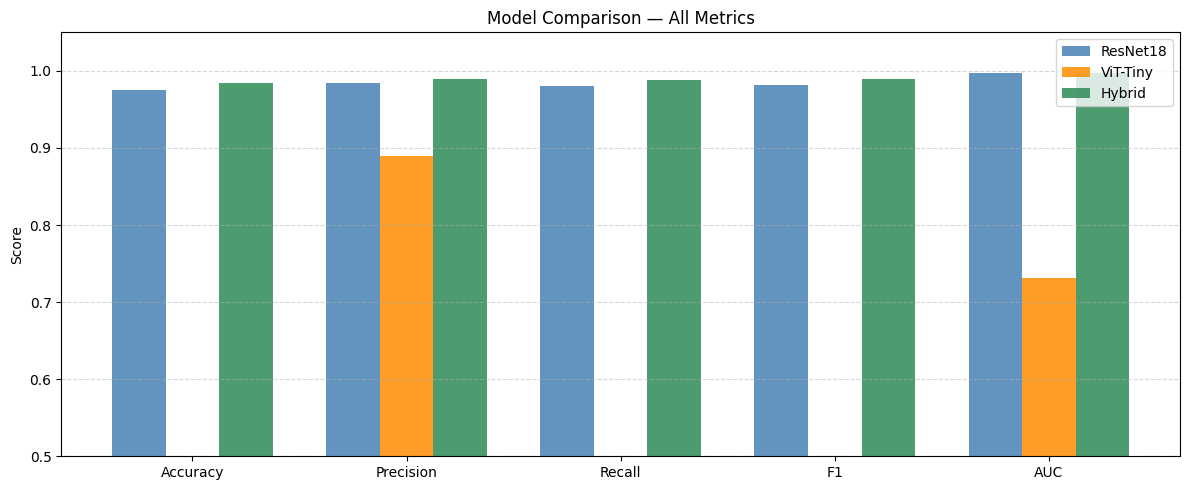

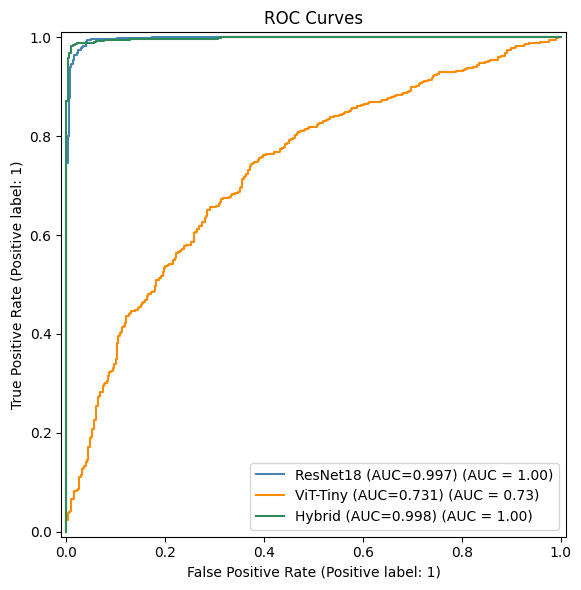

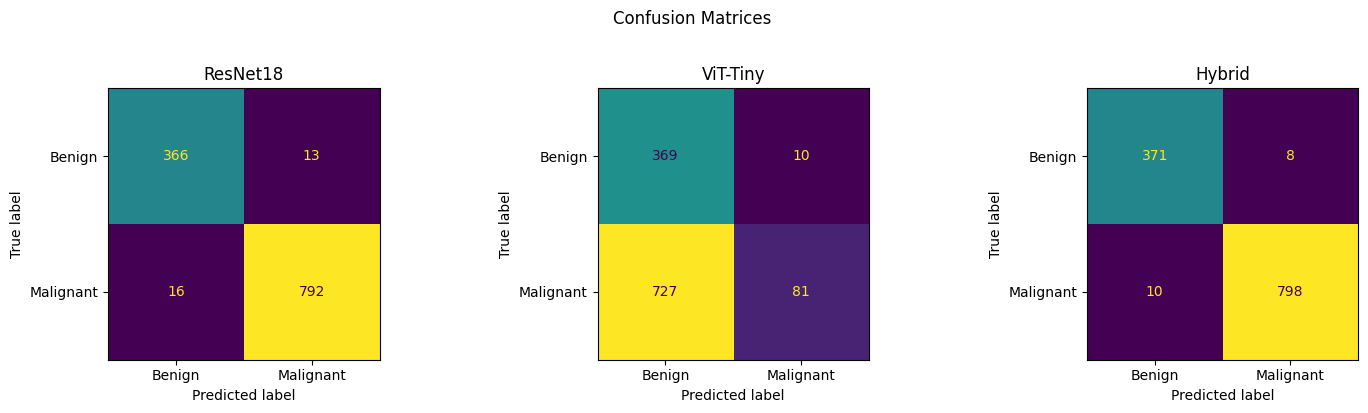

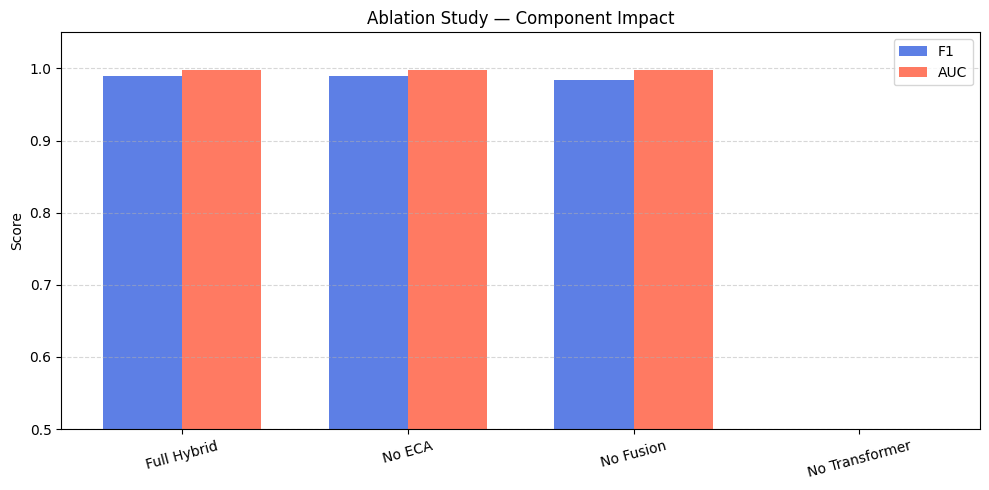

Visualizations complete.


In [49]:
# =========================
# 🔷 WEEK 5: VISUALIZATIONS
# =========================

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, confusion_matrix

model_names  = ["ResNet18", "ViT-Tiny", "Hybrid"]
model_results = [results_cnn, results_vit, results_hybrid]
colors        = ["steelblue", "darkorange", "seagreen"]

# 🔹 1. Bar Chart — Metric Comparison
metrics_to_plot = ["acc", "precision", "recall", "f1", "auc"]
metric_labels   = ["Accuracy", "Precision", "Recall", "F1", "AUC"]

x  = np.arange(len(metrics_to_plot))
w  = 0.25

fig, ax = plt.subplots(figsize=(12, 5))
for i, (name, res, c) in enumerate(zip(model_names, model_results, colors)):
    vals = [res[m] for m in metrics_to_plot]
    ax.bar(x + i*w, vals, w, label=name, color=c, alpha=0.85)

ax.set_xticks(x + w)
ax.set_xticklabels(metric_labels)
ax.set_ylim(0.5, 1.05)
ax.set_ylabel("Score")
ax.set_title("Model Comparison — All Metrics")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# 🔹 2. ROC Curves — All Three Models
fig, ax = plt.subplots(figsize=(7, 6))
for name, res, c in zip(model_names, model_results, colors):
    RocCurveDisplay.from_predictions(
        res["y_true"], res["y_score"],
        name=f"{name} (AUC={res['auc']:.3f})",
        color=c, ax=ax
    )
ax.set_title("ROC Curves")
plt.tight_layout()
plt.show()

# 🔹 3. Confusion Matrices — All Three Models
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name, res in zip(axes, model_names, model_results):
    cm = confusion_matrix(res["y_true"], [round(s) for s in res["y_score"]])
    ConfusionMatrixDisplay(cm, display_labels=["Benign", "Malignant"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.suptitle("Confusion Matrices", y=1.02)
plt.tight_layout()
plt.show()

# 🔹 4. Ablation Bar Chart — F1 & AUC
abl_names = list(ablation_results.keys())
abl_f1    = [ablation_results[n]["f1"]  for n in abl_names]
abl_auc   = [ablation_results[n]["auc"] for n in abl_names]

x  = np.arange(len(abl_names))
w  = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - w/2, abl_f1,  w, label="F1",  color="royalblue", alpha=0.85)
ax.bar(x + w/2, abl_auc, w, label="AUC", color="tomato",    alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(abl_names, rotation=15)
ax.set_ylim(0.5, 1.05)
ax.set_ylabel("Score")
ax.set_title("Ablation Study — Component Impact")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print("Visualizations complete.")